In [70]:
#Import librairies
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math 
from scipy.stats import pearsonr
import scipy.stats as stats
from plotly.subplots import make_subplots
from scipy.stats import shapiro
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
from sklearn import preprocessing
from sklearn.feature_selection import RFE
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings("ignore") 
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
from sklearn import preprocessing
import plotly.graph_objects as go
import plotly.express as px
import missingno as msno
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import skew, shapiro
from scipy.stats import boxcox
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import StandardScaler
import itertools
from sklearn.feature_selection import mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
import shap
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import MinMaxScaler
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import EditedNearestNeighbours
from collections import Counter
from sklearn.feature_selection import SelectKBest
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from prettytable import PrettyTable
import featuretools as ft
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import lightgbm as lgb

In [71]:
#import data
data = pd.read_csv(
    'C:/Users/Mega-Pc/Freelance/data/ecommerce/data_cleaned+scaled.csv',encoding='ISO-8859-1')

In [72]:
# aggregate numeric features per customer
customer_features = data.groupby('CustomerID').agg(
    TotalPurchases=('TotalPrice','sum'),
    AvgPurchaseValue=('TotalPrice','mean'),
    AvgSentiment=('SentimentScore','mean'),
    NumDeluxeProducts=('IsDeluxe','sum'),
    NumClustersPurchased=('ProductClusterSemantic','nunique'),
    DaysSinceFirstPurchase=('DaysSinceFirstPurchase','max')
).reset_index()


print(customer_features.head())


   CustomerID  TotalPurchases  AvgPurchaseValue  AvgSentiment  \
0    0.000000        0.698533          0.349267      0.722222   
1    0.000168       72.074800          0.396015      0.448499   
2    0.000337       11.933567          0.384954      0.436081   
3    0.000505       28.180500          0.386034      0.475420   
4    0.000673        6.531333          0.384196      0.450980   

   NumDeluxeProducts  NumClustersPurchased  DaysSinceFirstPurchase  
0                0.0                     1                0.000000  
1                2.0                     5                0.978552  
2                0.0                     2                0.756032  
3                2.0                     5                0.000000  
4                0.0                     4                0.000000  


In [73]:
# target = total revenue per customer
customer_features['CLV'] = customer_features['TotalPurchases']


In [74]:
# split data

X = customer_features.drop(columns=['CustomerID','CLV'])
y = customer_features['CLV']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)


Training set: (3497, 6)
Test set: (875, 6)


## Model = LightGBM

In [44]:
import optuna
import lightgbm as lgb
from lightgbm import early_stopping, log_evaluation
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def objective(trial):
    params = {
        'objective': 'regression',
        'metric': 'rmse',
        'boosting_type': 'gbdt',
        'verbosity': -1,
        'seed': 42,
        'learning_rate': trial.suggest_float('learning_rate', 0.03, 0.07, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 100, 180),
        'max_depth': trial.suggest_int('max_depth', 8, 12),
        'min_data_in_leaf': trial.suggest_int('min_data_in_leaf', 20, 50),
        'feature_fraction': trial.suggest_float('feature_fraction', 0.6, 0.8),
        'bagging_fraction': trial.suggest_float('bagging_fraction', 0.8, 0.9),
        'bagging_freq': trial.suggest_int('bagging_freq', 5, 10),
        'lambda_l1': trial.suggest_float('lambda_l1', 4.0, 6.0),
        'lambda_l2': trial.suggest_float('lambda_l2', 3.5, 6.0),
        'min_gain_to_split': trial.suggest_float('min_gain_to_split', 0.7, 1.0),
    }


    train_data = lgb.Dataset(X_train, label=y_train)
    test_data = lgb.Dataset(X_test, label=y_test, reference=train_data)


    gbm = lgb.train(
        params,
        train_data,
        valid_sets=[test_data],
        callbacks=[
            early_stopping(stopping_rounds=150),  
            log_evaluation(period=0)
        ]
    )

    
    y_pred = gbm.predict(X_test, num_iteration=gbm.best_iteration)
    rmse = mean_squared_error(y_test, y_pred, squared=False)
    return rmse


study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100, show_progress_bar=True)

# best params
print("✅ Best trial:")
print(f"  RMSE: {study.best_trial.value:.4f}")
for key, value in study.best_trial.params.items():
    print(f"    {key}: {value}")


best_params = study.best_trial.params
best_params.update({
    'objective': 'regression',
    'metric': 'rmse',
    'boosting_type': 'gbdt',
    'verbosity': -1,
    'seed': 42
})

train_data = lgb.Dataset(X_train, label=y_train)
test_data = lgb.Dataset(X_test, label=y_test, reference=train_data)

model = lgb.train(
    best_params,
    train_data,
    valid_sets=[test_data],
    callbacks=[
        early_stopping(stopping_rounds=150),
        log_evaluation(period=50)
    ]
)


y_pred = model.predict(X_test, num_iteration=model.best_iteration)
rmse = mean_squared_error(y_test, y_pred, squared=False)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\nFinal model performance:")
print(f"RMSE: {rmse:.2f}, MAE: {mae:.2f}, R²: {r2:.2f}")

[I 2025-10-15 11:59:18,793] A new study created in memory with name: no-name-3931d85a-8ca7-447e-bb75-74281a4ec1d2


  0%|          | 0/100 [00:00<?, ?it/s]

Training until validation scores don't improve for 150 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's rmse: 83.005
[I 2025-10-15 11:59:18,897] Trial 0 finished with value: 83.00498993595167 and parameters: {'learning_rate': 0.03568940700518455, 'num_leaves': 138, 'max_depth': 8, 'min_data_in_leaf': 27, 'feature_fraction': 0.6798002144840113, 'bagging_fraction': 0.8685442768209853, 'bagging_freq': 8, 'lambda_l1': 4.265739738263203, 'lambda_l2': 3.7283593906243078, 'min_gain_to_split': 0.8847965656480056}. Best is trial 0 with value: 83.00498993595167.
Training until validation scores don't improve for 150 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's rmse: 86.5883
[I 2025-10-15 11:59:18,963] Trial 1 finished with value: 86.58830188669658 and parameters: {'learning_rate': 0.030245471683097738, 'num_leaves': 156, 'max_depth': 8, 'min_data_in_leaf': 34, 'feature_fraction': 0.6433023838383262, 'bagging_fraction': 0.8315276371878032, 'bagging_

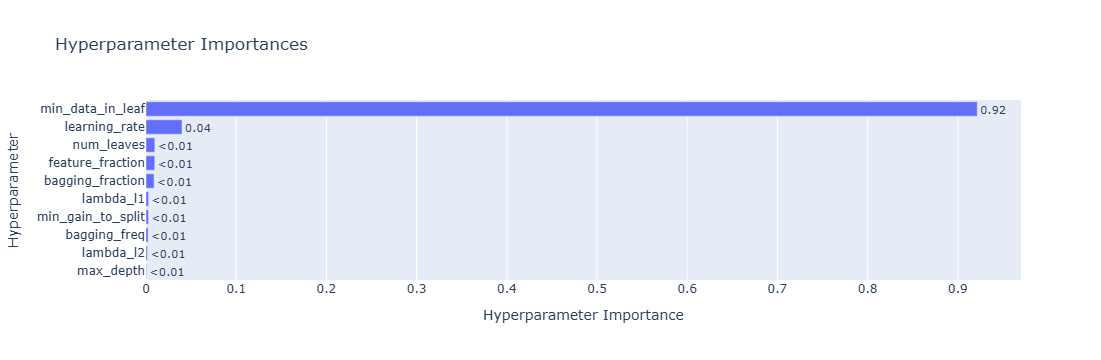

In [47]:
optuna.visualization.plot_optimization_history(study)
optuna.visualization.plot_param_importances(study)


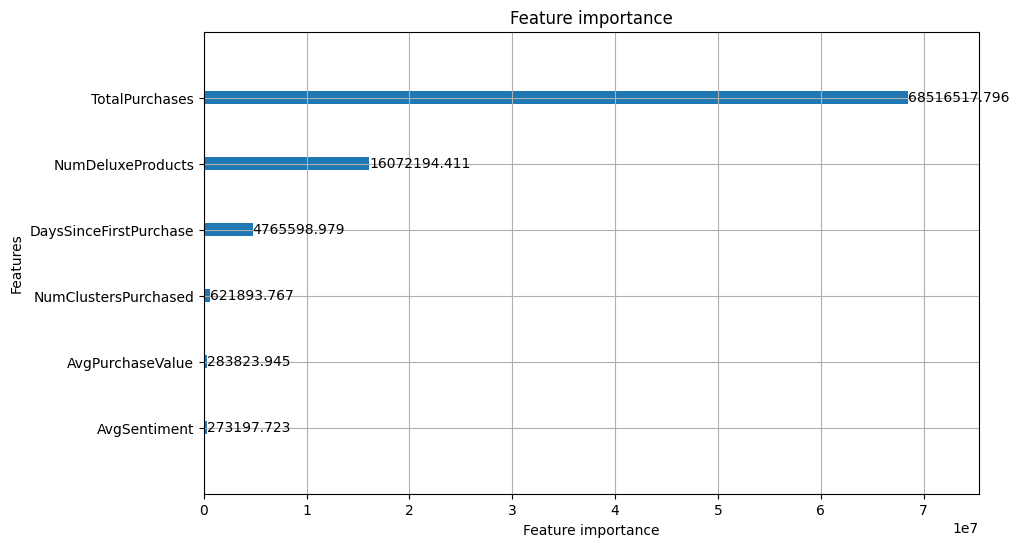

In [48]:
lgb.plot_importance(model, max_num_features=20, importance_type='gain', figsize=(10,6))
plt.show()


### LightGBM Final Model Performance

- **RMSE:** 72.12  
- **MAE:** 7.10  
- **R²:** 0.62


## Model = XgBoost

In [75]:
import xgboost as xgb


def objective(trial):
    params = {
        'objective': 'reg:squarederror',
        'eval_metric': 'rmse',
        'tree_method': 'hist',
        'seed': 42,
        'learning_rate': trial.suggest_float('learning_rate', 0.03, 0.07, log=True),
        'max_depth': trial.suggest_int('max_depth', 6, 12),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 8),
        'subsample': trial.suggest_float('subsample', 0.7, 0.9),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 0.8),
        'lambda': trial.suggest_float('lambda', 1.0, 5.0),
        'alpha': trial.suggest_float('alpha', 0.0, 3.0),
        'gamma': trial.suggest_float('gamma', 0.0, 1.0),
        'n_estimators': trial.suggest_int('n_estimators', 400, 800),
    }

    model = xgb.XGBRegressor(**params, verbosity=0)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    rmse = mean_squared_error(y_test, y_pred, squared=False)
    return rmse


study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100, show_progress_bar=True)

print("✅ Best trial:")
print(f"  RMSE: {study.best_trial.value:.4f}")
for key, value in study.best_trial.params.items():
    print(f"    {key}: {value}")

best_params = study.best_trial.params
best_params.update({'objective': 'reg:squarederror', 'seed': 42})

final_model = xgb.XGBRegressor(**best_params)
final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)
rmse = mean_squared_error(y_test, y_pred, squared=False)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\nFinal model performance:")
print(f"RMSE: {rmse:.2f}, MAE: {mae:.2f}, R²: {r2:.2f}")

[I 2025-10-15 12:18:23,729] A new study created in memory with name: no-name-b82d91d7-08b1-4db3-856a-30588ff98f45


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2025-10-15 12:18:24,281] Trial 0 finished with value: 53.30640069278247 and parameters: {'learning_rate': 0.05523431994798373, 'max_depth': 7, 'min_child_weight': 6, 'subsample': 0.8438812088259541, 'colsample_bytree': 0.6591192474271522, 'lambda': 1.363428435009748, 'alpha': 0.8213922852651752, 'gamma': 0.8562737507518126, 'n_estimators': 628}. Best is trial 0 with value: 53.30640069278247.
[I 2025-10-15 12:18:25,021] Trial 1 finished with value: 42.41434484377955 and parameters: {'learning_rate': 0.03710118187347533, 'max_depth': 11, 'min_child_weight': 2, 'subsample': 0.7970032992722278, 'colsample_bytree': 0.641742145745459, 'lambda': 1.136784121858709, 'alpha': 0.35880745691610705, 'gamma': 0.6989496833022467, 'n_estimators': 481}. Best is trial 1 with value: 42.41434484377955.
[I 2025-10-15 12:18:25,519] Trial 2 finished with value: 51.264709630801924 and parameters: {'learning_rate': 0.06412055948615933, 'max_depth': 7, 'min_child_weight': 3, 'subsample': 0.8712156025583542, 

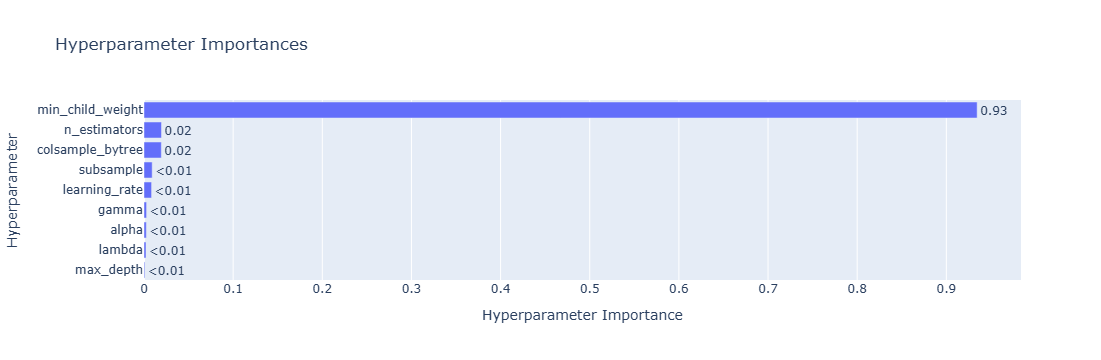

In [77]:
optuna.visualization.plot_optimization_history(study)
optuna.visualization.plot_param_importances(study)


### XGBoost Final Model Performance

- **RMSE:** 32.16  
- **MAE:** 2.98  
- **R²:** 0.93


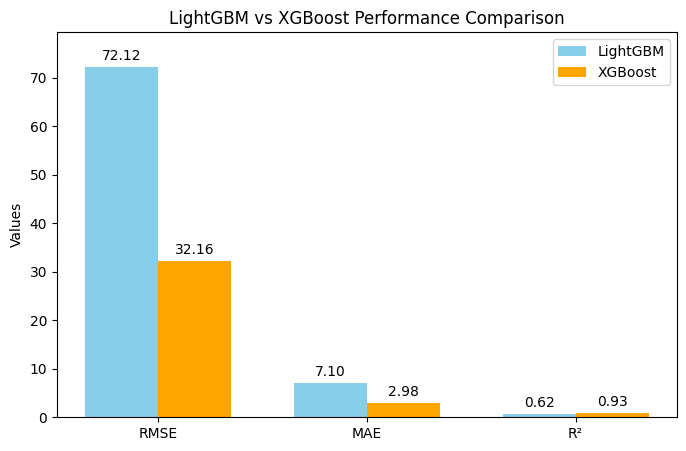

In [78]:
# Metrics
metrics = ['RMSE', 'MAE', 'R²']
lightgbm_values = [72.12, 7.10, 0.62]
xgboost_values = [32.16, 2.98, 0.93]

x = np.arange(len(metrics)) 
width = 0.35  

fig, ax = plt.subplots(figsize=(8,5))
rects1 = ax.bar(x - width/2, lightgbm_values, width, label='LightGBM', color='skyblue')
rects2 = ax.bar(x + width/2, xgboost_values, width, label='XGBoost', color='orange')


ax.set_ylabel('Values')
ax.set_title('LightGBM vs XGBoost Performance Comparison')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width()/2, height),
                    xytext=(0,3),
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

plt.ylim(0, max(lightgbm_values + xgboost_values)*1.1)
plt.show()


### Comparison Between LightGBM and XGBoost

| Metric | LightGBM | XGBoost |
|--------|----------|---------|
| RMSE   | 72.12    | 32.16   |
| MAE    | 7.10     | 2.98    |
| R²     | 0.62     | 0.93    |

**Remark:**  
- XGBoost significantly outperforms LightGBM on this dataset in terms of accuracy.  
- RMSE and MAE are much lower, and R² is much closer to 1.  
- XGBoost is therefore the better choice for this regression problem.


## Model = CatBoost

In [17]:
from catboost import CatBoostRegressor, Pool


def objective(trial):
    params = {
        'iterations': trial.suggest_int('iterations', 400, 800),
        'learning_rate': trial.suggest_float('learning_rate', 0.03, 0.07, log=True),
        'depth': trial.suggest_int('depth', 6, 12),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 5.0),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0.0, 1.0),
        'random_strength': trial.suggest_float('random_strength', 0.0, 2.0),
        'border_count': trial.suggest_int('border_count', 32, 255),
        'loss_function': 'RMSE',
        'eval_metric': 'RMSE',
        'random_seed': 42,
        'verbose': 0
    }

    model = CatBoostRegressor(**params)
    model.fit(X_train, y_train, eval_set=(X_test, y_test), use_best_model=True)

    y_pred = model.predict(X_test)
    rmse = mean_squared_error(y_test, y_pred, squared=False)
    return rmse

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100, show_progress_bar=True)

# best params
print("✅ Best trial:")
print(f"  RMSE: {study.best_trial.value:.4f}")
for key, value in study.best_trial.params.items():
    print(f"    {key}: {value}")

best_params = study.best_trial.params
best_params.update({
    'loss_function': 'RMSE',
    'eval_metric': 'RMSE',
    'random_seed': 42,
    'verbose': 50
})

final_model = CatBoostRegressor(**best_params)
final_model.fit(X_train, y_train, eval_set=(X_test, y_test), use_best_model=True)

#evaluate
y_pred = final_model.predict(X_test)
rmse = mean_squared_error(y_test, y_pred, squared=False)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\nCatBoost Final model performance:")
print(f"RMSE: {rmse:.2f}, MAE: {mae:.2f}, R²: {r2:.2f}")


[I 2025-10-15 11:23:49,094] A new study created in memory with name: no-name-8d6c2643-3ce5-4012-8583-861a85ff732e


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2025-10-15 11:23:54,915] Trial 0 finished with value: 45.61050518825054 and parameters: {'iterations': 678, 'learning_rate': 0.06569576834068341, 'depth': 10, 'l2_leaf_reg': 4.572044008195651, 'bagging_temperature': 0.15651294762407453, 'random_strength': 1.0245750675962981, 'border_count': 146}. Best is trial 0 with value: 45.61050518825054.
[I 2025-10-15 11:23:56,972] Trial 1 finished with value: 79.31186536916734 and parameters: {'iterations': 732, 'learning_rate': 0.055111314019475, 'depth': 9, 'l2_leaf_reg': 3.505479058891883, 'bagging_temperature': 0.37380829004048366, 'random_strength': 0.048103062760856075, 'border_count': 62}. Best is trial 0 with value: 45.61050518825054.
[I 2025-10-15 11:23:57,750] Trial 2 finished with value: 44.48972583329627 and parameters: {'iterations': 433, 'learning_rate': 0.032818779156310686, 'depth': 6, 'l2_leaf_reg': 3.8171037570632094, 'bagging_temperature': 0.331945563054184, 'random_strength': 1.618892194497033, 'border_count': 187}. Best is

### CatBoost Final Model Performance

- **RMSE:** 29.90  
- **MAE:** 3.02  
- **R²:** 0.94


## Scatter plot version to visualize Actual vs Predicted CLV

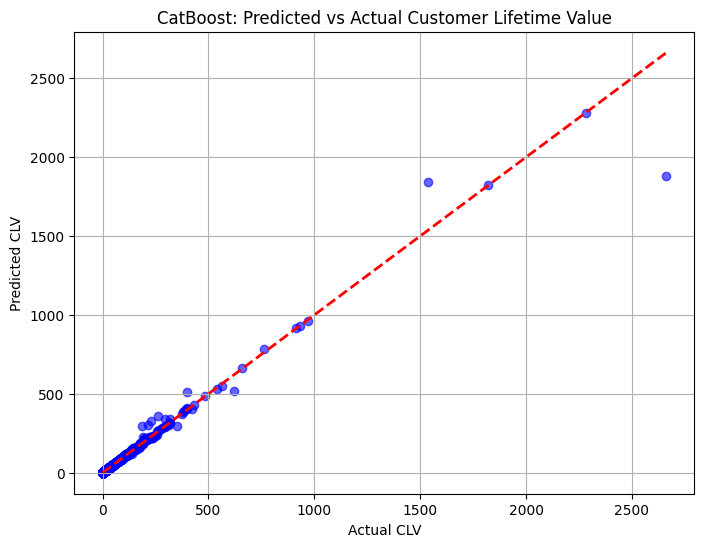

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(predictions['Actual_CLV'], predictions['Predicted_CLV'], alpha=0.6, color='blue')
plt.plot([predictions['Actual_CLV'].min(), predictions['Actual_CLV'].max()],
         [predictions['Actual_CLV'].min(), predictions['Actual_CLV'].max()],
         'r--', lw=2)  # 45° reference line
plt.xlabel('Actual CLV')
plt.ylabel('Predicted CLV')
plt.title('CatBoost: Predicted vs Actual Customer Lifetime Value')
plt.grid(True)
plt.show()


      CustomerID   Actual_CLV  Predicted_CLV
1895    0.431745  2283.553567    2219.080078
1300    0.294563  1821.465300    1866.765015
4042    0.924928  2662.209333    1859.085327
330     0.067665  1535.622500    1046.887817
1703    0.387140   968.145400     966.038696
568     0.125063   760.773867     951.522644
2192    0.499074   913.265967     940.207581
1674    0.380407   931.355300     934.950500
1345    0.304663   619.555333     798.785461
1447    0.328564   660.772033     653.114868


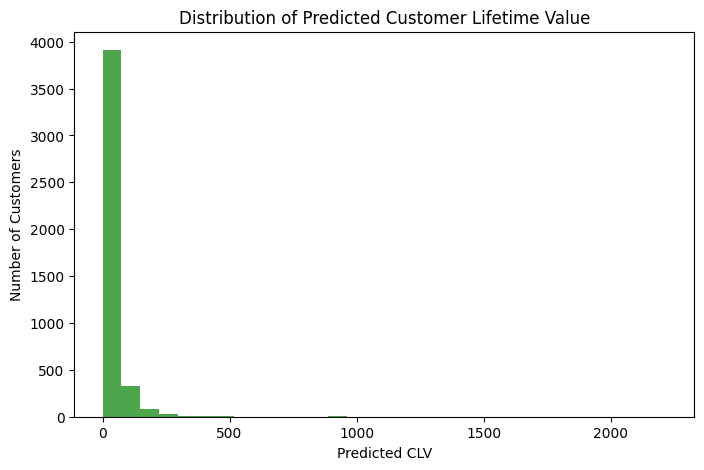

In [79]:
X_customers = customer_features.drop(columns=['CustomerID', 'CLV'])
y_customers = customer_features['CLV']

predicted_clv = final_model.predict(X_customers)

predictions = pd.DataFrame({
    'CustomerID': customer_features['CustomerID'],
    'Actual_CLV': y_customers,
    'Predicted_CLV': predicted_clv
})


print(predictions.sort_values(by='Predicted_CLV', ascending=False).head(10))

plt.figure(figsize=(8,5))
plt.hist(predictions['Predicted_CLV'], bins=30, color='green', alpha=0.7)
plt.xlabel('Predicted CLV')
plt.ylabel('Number of Customers')
plt.title('Distribution of Predicted Customer Lifetime Value')
plt.show()


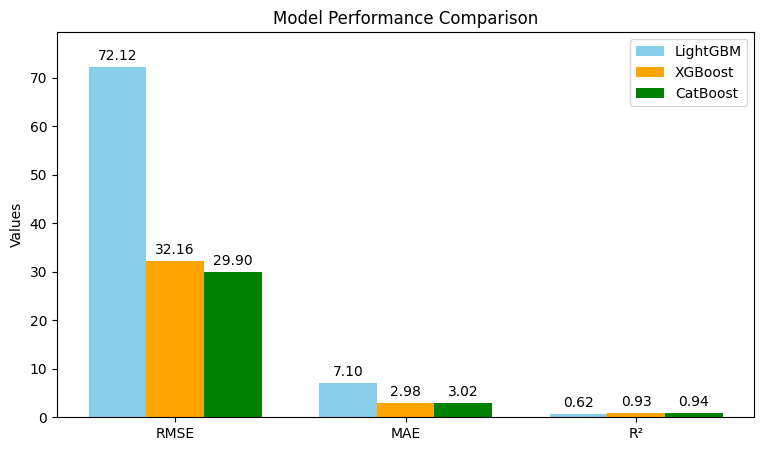

In [18]:
import matplotlib.pyplot as plt
import numpy as np


metrics = ['RMSE', 'MAE', 'R²']
lightgbm_values = [72.12, 7.10, 0.62]
xgboost_values = [32.16, 2.98, 0.93]
catboost_values = [29.90, 3.02, 0.94]

x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(9,5))
rects1 = ax.bar(x - width, lightgbm_values, width, label='LightGBM', color='skyblue')
rects2 = ax.bar(x, xgboost_values, width, label='XGBoost', color='orange')
rects3 = ax.bar(x + width, catboost_values, width, label='CatBoost', color='green')


ax.set_ylabel('Values')
ax.set_title('Model Performance Comparison')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()

# Annotate bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width()/2, height),
                    xytext=(0,3),
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

plt.ylim(0, max(lightgbm_values + xgboost_values + catboost_values)*1.1)
plt.show()


### Conclusion

- **LightGBM** performed the weakest with the highest RMSE (72.12) and lowest R² (0.62).  
- **XGBoost** significantly improved performance, achieving RMSE = 32.16 and R² = 0.93.  
- **CatBoost** slightly outperformed XGBoost with the lowest RMSE (29.90) and highest R² (0.94).  

**Remark:**  
For this regression problem, **CatBoost is the best choice** due to its ability to handle categorical features natively and provide the highest predictive accuracy.
